# Đề tài 13 — Phân loại chữ số viết tay (Digits)

**Khung hỗ trợ học tập, chưa phải bài nộp hoàn chỉnh.** Đã đối chiếu toàn bộ 6 trang
`docs/Huong_Dan_Do_An_CuoiKy.pdf`, đặc biệt mục 5–6, thang điểm và 5 câu hỏi trang 5–6.
Mã hỗ trợ do Codex tạo; các ô `student-core` là phần nhóm phải tự triển khai, kiểm thử,
giải thích và ghi vào `AI_USAGE.md`. Không dùng AI viết thay nhận định.

Chạy từ thư mục gốc project. Mặc định chỉ chạy kiểm tra dữ liệu, split và EDA;
không fit mô hình, không tạo điểm số giả. Chỉ đổi `RUN_STUDENT_EXPERIMENTS` khi đã hoàn thành TODO.


## 1. Bài toán, mục tiêu và tiêu chí thành công

Học có giám sát, phân lớp đa lớp: một ảnh → nhãn nguyên 0–9. Dữ liệu Digits là ảnh 8×8,
không phải MNIST 28×28. Mục tiêu: so sánh Logistic Regression trên pixel thô với KNN và MLP;
kiểm chứng tác động chuẩn hóa, xem nhầm lẫn và chi phí tính toán.

Quy tắc chọn **đặt trước khi chạy**: macro F1 trung bình CV cao nhất; hòa tuyệt đối chọn tên
mô hình theo thứ tự chữ cái để tái lập. Không bắt buộc MLP phải thắng. Tiêu chí thành công:
quy trình tái lập, không rò rỉ, đủ so sánh với baseline và trả lời được 5 câu hỏi bằng bằng chứng.
Macro F1 cân bằng đóng góp 10 lớp; accuracy dễ hiểu; precision/recall macro giúp xem loại sai khác nhau.
Nhóm tự giải thích lựa chọn độ đo và thống nhất tiêu chí này trước thí nghiệm.

**Nhóm tự viết:** mục đích sử dụng, lý do chọn độ đo, phạm vi áp dụng, thành viên và phân công thực tế.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
from time import perf_counter
from io import BytesIO
import hashlib
import json
import platform
import sys
import uuid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, cross_validate, learning_curve,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
from threadpoolctl import threadpool_limits

SEED = 42
LABELS = np.arange(10)
RUN_STUDENT_EXPERIMENTS = False
# Điền sau khi xem kiểm tra dữ liệu; không dùng cờ này thay cho nhật ký quyết định.
CLEANING_DECISION = ""
STUDENT_PROTOCOL_NOTE = ""
SELECTION_RULE = "highest_cv_f1_macro_mean_then_name_ascending"
ROOT = Path.cwd()
assert (ROOT / "docs/Huong_Dan_Do_An_CuoiKy.pdf").is_file(), "Mở notebook từ gốc project."
# Mỗi lần chạy tạo thư mục riêng, giữ nguyên kết quả cũ.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
OUT = ROOT / "outputs" / RUN_ID
MODEL_OUT = ROOT / "models" / RUN_ID
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=False)
PACKAGES = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "joblib",
            "notebook", "ipykernel", "nbformat", "nbclient", "scipy", "threadpoolctl"]
environment = {"python": sys.version, "platform": platform.platform(),
               "packages": {name: version(name) for name in PACKAGES},
               "seed": SEED, "run_id": RUN_ID, "selection_rule": SELECTION_RULE,
               "student_experiments_requested": RUN_STUDENT_EXPERIMENTS}
(OUT / "environment.json").write_text(json.dumps(environment, indent=2, ensure_ascii=False), encoding="utf-8")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
pd.set_option("display.max_rows", 70)
print("Run:", RUN_ID, "| Chế độ:", "thực nghiệm sinh viên" if RUN_STUDENT_EXPERIMENTS else "khung hỗ trợ")


def save_figure(fig, filename):
    fig.savefig(FIGURES / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


Run: 20261117T070246Z_4ebb5029 | Chế độ: khung hỗ trợ


## 2. Đọc dữ liệu và ghi nguồn

Nguồn chính thức: [scikit-learn load_digits](https://scikit-learn.org/1.7/modules/generated/sklearn.datasets.load_digits.html),
[UCI Optical Recognition of Handwritten Digits](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits).
`load_digits()` đóng gói dữ liệu trong scikit-learn, không cần tải MNIST. Ghi lại DESCR đi kèm bản cài
để tra nguồn gốc. Dữ liệu chứa ảnh số, không sử dụng thông tin cá nhân của nhóm.


In [2]:
digits = load_digits()
X = pd.DataFrame(digits.data, columns=digits.feature_names)
y = pd.Series(digits.target, name="target")
raw_data = X.assign(target=y)
schema = pd.DataFrame({"dtype": raw_data.dtypes.astype(str),
                       "missing_count": raw_data.isna().sum(),
                       "missing_ratio": raw_data.isna().mean()})
data_summary = {"X_shape": list(X.shape), "images_shape": list(digits.images.shape),
                "y_shape": list(y.shape), "n_samples": len(X), "n_features": X.shape[1],
                "labels": sorted(y.unique().tolist()), "pixel_min": float(X.min().min()),
                "pixel_max": float(X.max().max()), "X_dtype": str(digits.data.dtype),
                "y_dtype": str(y.dtype)}
display(pd.Series(data_summary, name="giá trị"))
display(schema)
schema.to_csv(OUT / "column_schema.csv", encoding="utf-8-sig", index_label="column")
(OUT / "data_summary.json").write_text(json.dumps(data_summary, indent=2), encoding="utf-8")
(OUT / "dataset_description.txt").write_text(digits.DESCR, encoding="utf-8")
DATA_SHA256 = hashlib.sha256(np.ascontiguousarray(X).tobytes() + np.ascontiguousarray(y).tobytes()).hexdigest()
print("SHA256 dữ liệu (X rồi y):", DATA_SHA256)


X_shape                             [1797, 64]
images_shape                      [1797, 8, 8]
y_shape                                 [1797]
n_samples                                 1797
n_features                                  64
labels          [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
pixel_min                                  0.0
pixel_max                                 16.0
X_dtype                                float64
y_dtype                                  int64
Name: giá trị, dtype: object

,dtype,missing_count,missing_ratio
pixel_0_0,float64,0,0.0
pixel_0_1,float64,0,0.0
pixel_0_2,float64,0,0.0
pixel_0_3,float64,0,0.0
pixel_0_4,float64,0,0.0
pixel_0_5,float64,0,0.0
pixel_0_6,float64,0,0.0
pixel_0_7,float64,0,0.0
pixel_1_0,float64,0,0.0
pixel_1_1,float64,0,0.0


SHA256 dữ liệu (X rồi y): f6d9e39f37dc45d327f6db33428ee58970ccceabb2535a5c179de35886b70443


## 3. Kiểm tra chất lượng và quyết định xử lý

Kiểu lưu float của pixel không có nghĩa là sai kiểu: cần kiểm tra giá trị số, hữu hạn, nguyên
trong miền 0–16. Nhãn phải nguyên 0–9. Ảnh toàn 0 hoặc hằng là ứng viên cần xem xét;
không tự suy ra ảnh nét mảnh/đậm là lỗi. Chưa dùng thông tin test để chọn chính sách loại ảnh.

Ô dưới chỉ kiểm tra hợp lệ, không sửa hoặc loại mẫu. Mọi cờ cảnh báo phải được nhóm giải thích.
Nếu có thiếu/sai kiểu: xác minh nguồn; nếu cần impute, đặt imputer trong Pipeline và fit theo fold.
Nếu có ảnh trùng/nhãn mâu thuẫn: điều tra nguồn và ghi quyết định trước split. Không xóa ảnh khó.


In [3]:
numeric_X = X.apply(pd.to_numeric, errors="coerce")
numeric_y = pd.to_numeric(y, errors="coerce")
values = numeric_X.to_numpy()
finite_pixels = np.isfinite(values)
bad_pixel = (~finite_pixels) | (values < 0) | (values > 16) | (values != np.floor(values))
bad_labels = (~np.isfinite(numeric_y)) | (~numeric_y.isin(LABELS)) | (numeric_y != np.floor(numeric_y))
# Tuple giữ so sánh chính xác toàn bộ 64 pixel, không làm tròn hay chỉ so nhãn.
image_keys = pd.Series([tuple(row) for row in values], index=X.index, name="image_key")
duplicate_mask = image_keys.duplicated(keep=False)
label_conflicts = pd.DataFrame({"key": image_keys, "label": y}).groupby("key")["label"].nunique().gt(1)
constant_images = numeric_X.nunique(axis=1).le(1)
quality = {"missing_cells": int(raw_data.isna().sum().sum()),
           "nonnumeric_pixels": int((numeric_X.isna() & X.notna()).sum().sum()),
           "invalid_pixel_cells": int(bad_pixel.sum()), "invalid_labels": int(bad_labels.sum()),
           "duplicate_image_rows": int(duplicate_mask.sum()),
           "duplicate_extra_rows": int(image_keys.duplicated().sum()),
           "conflicting_image_groups": int(label_conflicts.sum()),
           "constant_images": int(constant_images.sum())}
display(pd.Series(quality, name="số lượng"))
(OUT / "data_quality.json").write_text(json.dumps(quality, indent=2), encoding="utf-8")
pd.DataFrame({"sample_index": X.index, "duplicate": duplicate_mask,
              "constant_image": constant_images}).to_csv(OUT / "quality_flags.csv", index=False)
assert not bad_pixel.any(), "Có pixel không hợp lệ; nhóm cần điều tra trước khi tiếp tục."
assert not bad_labels.any(), "Có nhãn không hợp lệ; nhóm cần điều tra."
assert not label_conflicts.any(), "Có ảnh cùng pixel khác nhãn; nhóm cần điều tra."
assert X.shape[1] == 64 and np.array_equal(values.reshape(-1, 8, 8), digits.images)


missing_cells               0
nonnumeric_pixels           0
invalid_pixel_cells         0
invalid_labels              0
duplicate_image_rows        0
duplicate_extra_rows        0
conflicting_image_groups    0
constant_images             0
Name: số lượng, dtype: int64

**Nhật ký do nhóm tự điền, không xem ô trống là quyết định đã thông qua:**

| Vấn đề | Bằng chứng từ output | Quyết định giữ/sửa/loại | Lý do | Người thực hiện |
|---|---|---|---|---|
| Thiếu / sai kiểu | TODO | TODO | TODO | TODO |
| Trùng / nhãn mâu thuẫn | TODO | TODO | TODO | TODO |
| Pixel ngoài miền / ảnh bất thường | TODO | TODO | TODO | TODO |

Sau khi kiểm tra, điền `CLEANING_DECISION` bằng quyết định có lý do. Nếu dữ liệu hợp lệ,
giữ nguyên là quyết định hợp lý khi có bằng chứng; không thêm imputer chỉ để có bước làm sạch.


## 4. Chia train/test và kiểm tra trùng xuyên tập

80/20, stratify=y, seed 42. Chỉ báo cáo kích thước và kiểm tra hợp lệ/trùng; không EDA test.
Kiểm tra cả CV để ảnh giống hệt không xuất hiện ở train và validation của fold.
Nếu phát hiện trùng, dừng và ghi quyết định; không âm thầm đổi chiến lược chia đã yêu cầu.


In [4]:
train_idx, test_idx = train_test_split(X.index.to_numpy(), test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test = X.loc[train_idx].copy(), X.loc[test_idx].copy()
y_train, y_test = y.loc[train_idx].copy(), y.loc[test_idx].copy()
overlap = set(image_keys.loc[train_idx]) & set(image_keys.loc[test_idx])
assert not (set(train_idx) & set(test_idx))
assert len(train_idx) + len(test_idx) == len(X)
assert not overlap, "Ảnh trùng xuyên train/test; cần nhóm quyết định xử lý trước khi huấn luyện."
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train))
fold_rows = []
for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    fit_keys = set(image_keys.loc[X_train.index[fit_idx]])
    val_keys = set(image_keys.loc[X_train.index[val_idx]])
    n_overlap = len(fit_keys & val_keys)
    assert n_overlap == 0, "Ảnh trùng xuyên CV; nhóm cần quyết định trước khi huấn luyện."
    assert len(np.unique(y_train.iloc[fit_idx])) == len(np.unique(y_train.iloc[val_idx])) == 10
    fold_rows.append({"fold": fold, "fit_n": len(fit_idx), "validation_n": len(val_idx), "overlap_images": n_overlap})
split_info = {"train_n": len(train_idx), "test_n": len(test_idx), "test_size": 0.2,
              "stratify": "y", "random_state": SEED, "overlap_images": len(overlap), "data_sha256": DATA_SHA256}
display(pd.Series(split_info))
display(pd.DataFrame(fold_rows))
pd.DataFrame({"sample_index": X.index, "split": np.where(X.index.isin(train_idx), "train", "test")}).to_csv(OUT / "split_indices.csv", index=False)
pd.DataFrame(fold_rows).to_csv(OUT / "cv_fold_audit.csv", index=False)
(OUT / "split_summary.json").write_text(json.dumps(split_info, indent=2), encoding="utf-8")


train_n                                                        1437
test_n                                                          360
test_size                                                       0.2
stratify                                                          y
random_state                                                     42
overlap_images                                                    0
data_sha256       f6d9e39f37dc45d327f6db33428ee58970ccceabb2535a...
dtype: object

,fold,fit_n,validation_n,overlap_images
0,1,1149,288,0
1,2,1149,288,0
2,3,1150,287,0
3,4,1150,287,0
4,5,1150,287,0


207

## 5. Sáu biểu đồ EDA chỉ trên train

Mã dựng biểu đồ là hỗ trợ trực quan; nhận định phải do nhóm tự viết, dẫn đúng hình/số liệu.
PCA chỉ phục vụ nhìn 2D, không đưa vào bộ mô hình của thí nghiệm này.


Kiểm tra bổ sung ảnh bất thường chỉ trên train: độ sáng trung bình và số pixel khác 0;
quy tắc IQR chỉ gắn cờ để xem, không tự loại ảnh. Nhóm gọi `review_train_image(id)` để kiểm tra
ảnh gắn cờ hoặc ảnh sáng/tối cực trị, rồi tự ghi lý do giữ/sửa/loại vào nhật ký mục 3.


In [5]:
image_diagnostics = pd.DataFrame({
    "mean_intensity": X_train.mean(axis=1),
    "nonzero_pixels": X_train.ne(0).sum(axis=1),
    "constant_image": X_train.nunique(axis=1).le(1),
})
q1, q3 = image_diagnostics["mean_intensity"].quantile([0.25, 0.75])
iqr = q3 - q1
image_diagnostics["brightness_iqr_flag"] = ~image_diagnostics["mean_intensity"].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
image_diagnostics.to_csv(OUT / "train_image_diagnostics.csv", index_label="sample_index")
print("Số ảnh train được gắn cờ IQR độ sáng (chưa kết luận lỗi):", int(image_diagnostics["brightness_iqr_flag"].sum()))
display(pd.concat([image_diagnostics.nsmallest(3, "mean_intensity"), image_diagnostics.nlargest(3, "mean_intensity")]))


def review_train_image(sample_index):
    """Nhóm tự gọi để xem bằng chứng; chỉ chấp nhận id trong train."""
    if sample_index not in X_train.index:
        raise ValueError("Chỉ xem ảnh train trước khi khóa mô hình")
    fig, ax = plt.subplots(figsize=(4, 4), layout="constrained")
    im = ax.imshow(X_train.loc[sample_index].to_numpy().reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.grid(False)
    ax.set(title=f"Kiểm tra ảnh train id={sample_index}, nhãn={y_train.loc[sample_index]}",
           xlabel="Cột pixel", ylabel="Hàng pixel")
    fig.colorbar(im, ax=ax, label="Cường độ pixel (0–16)")
    plt.show()
    plt.close(fig)

Số ảnh train được gắn cờ IQR độ sáng (chưa kết luận lỗi): 3


,mean_intensity,nonzero_pixels,constant_image,brightness_iqr_flag
1389,3.531250,25,False,False
1631,3.562500,22,False,False
1331,3.593750,28,False,False
818,6.765625,39,False,True
1747,6.671875,36,False,True
1766,6.546875,39,False,True


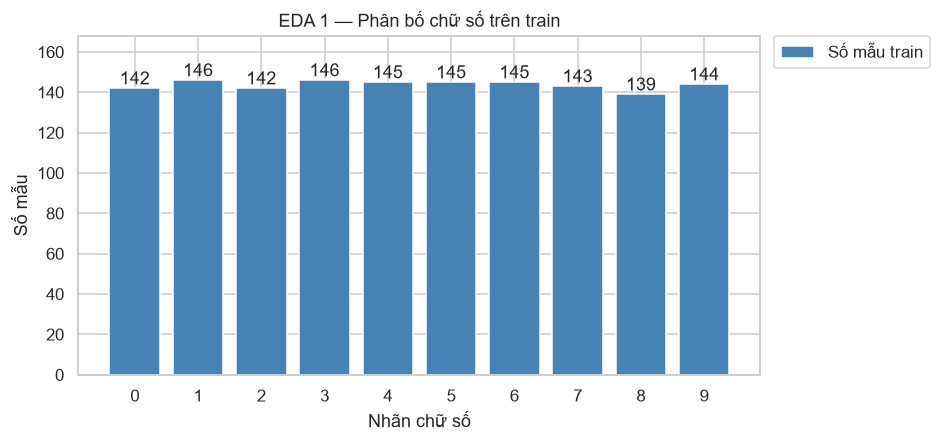

In [6]:
class_counts = y_train.value_counts().sort_index().reindex(LABELS, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_counts.index, class_counts.values, label="Số mẫu train", color="steelblue")
ax.set(title="EDA 1 — Phân bố chữ số trên train", xlabel="Nhãn chữ số", ylabel="Số mẫu", xticks=LABELS)
ax.bar_label(ax.containers[0])
ax.margins(y=0.15)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
save_figure(fig, "eda_01_class_distribution.png")
class_counts.to_csv(OUT / "train_class_counts.csv", index_label="label", header=["count"])


**Nhận định EDA 1 (nhóm tự viết):** TODO — mức cân bằng lớp, lớp nhiều/ít, ảnh hưởng lựa chọn độ đo.


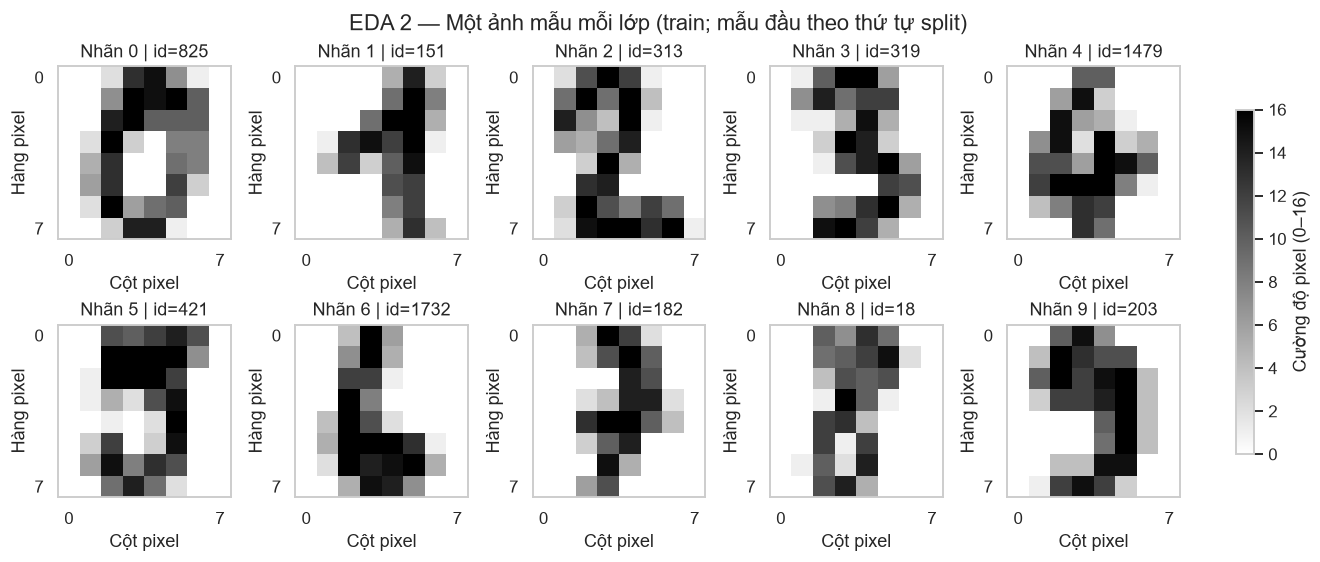

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5), layout="constrained")
for label, ax in zip(LABELS, axes.flat):
    sample_id = y_train[y_train == label].index[0]
    im = ax.imshow(X_train.loc[sample_id].to_numpy().reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.grid(False)
    ax.set(title=f"Nhãn {label} | id={sample_id}", xlabel="Cột pixel", ylabel="Hàng pixel", xticks=[0, 7], yticks=[0, 7])
fig.suptitle("EDA 2 — Một ảnh mẫu mỗi lớp (train; mẫu đầu theo thứ tự split)")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Cường độ pixel (0–16)", shrink=0.8)
save_figure(fig, "eda_02_sample_images.png")


**Nhận định EDA 2 (nhóm tự viết):** TODO — vector 64 chiều được khôi phục 8×8 thế nào; giới hạn độ phân giải.


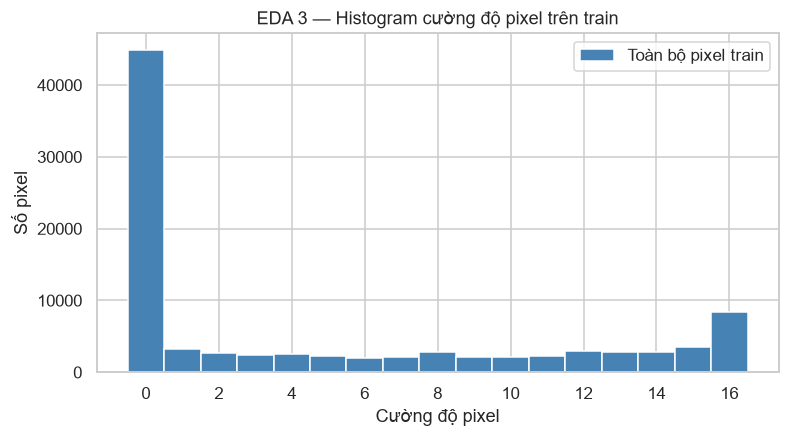

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(X_train.to_numpy().ravel(), bins=np.arange(-0.5, 17.5, 1), color="steelblue", label="Toàn bộ pixel train")
ax.set(title="EDA 3 — Histogram cường độ pixel trên train", xlabel="Cường độ pixel", ylabel="Số pixel", xticks=np.arange(0, 17, 2))
ax.legend()
save_figure(fig, "eda_03_pixel_histogram.png")


**Nhận định EDA 3 (nhóm tự viết):** TODO — miền pixel, giá trị phổ biến và ảnh hưởng nền ảnh; không suy ra cần xóa pixel 0.


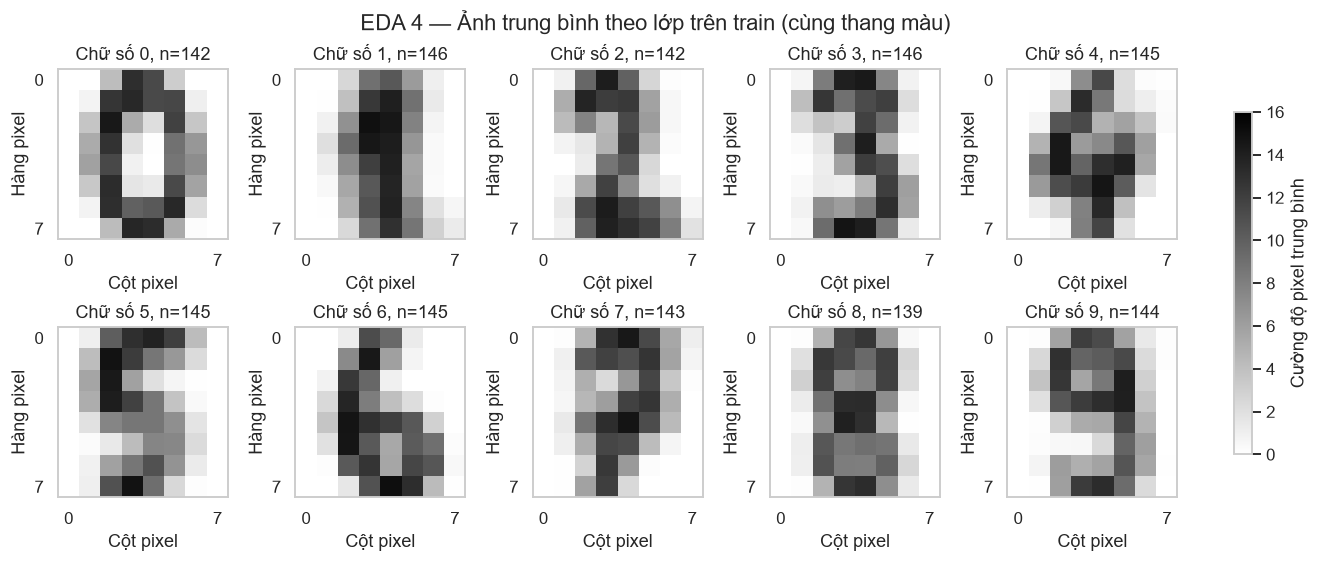

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5), layout="constrained")
for label, ax in zip(LABELS, axes.flat):
    mean_image = X_train.loc[y_train == label].mean().to_numpy().reshape(8, 8)
    im = ax.imshow(mean_image, cmap="gray_r", vmin=0, vmax=16)
    ax.grid(False)
    ax.set(title=f"Chữ số {label}, n={class_counts[label]}", xlabel="Cột pixel", ylabel="Hàng pixel", xticks=[0, 7], yticks=[0, 7])
fig.suptitle("EDA 4 — Ảnh trung bình theo lớp trên train (cùng thang màu)")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Cường độ pixel trung bình", shrink=0.8)
save_figure(fig, "eda_04_class_mean_images.png")


**Nhận định EDA 4 (nhóm tự viết):** TODO — vùng nét chung và lớp có hình dáng gần nhau; đây là giả thuyết, cần ma trận nhầm lẫn kiểm chứng.


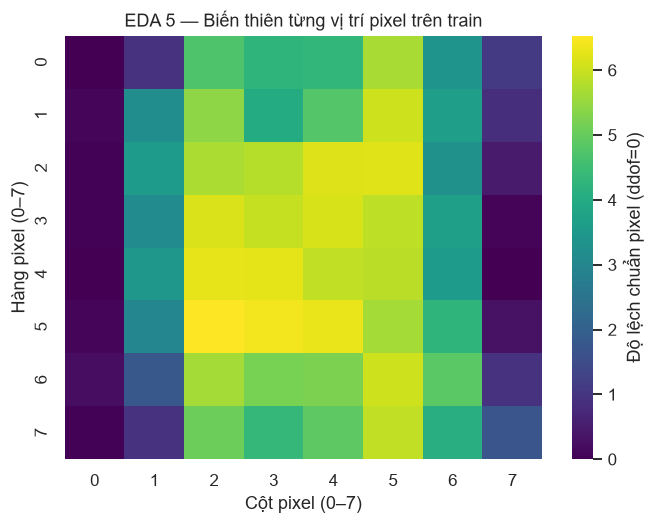

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
pixel_std = X_train.std(ddof=0).to_numpy().reshape(8, 8)
sns.heatmap(pixel_std, cmap="viridis", ax=ax, cbar_kws={"label": "Độ lệch chuẩn pixel (ddof=0)"})
ax.set(title="EDA 5 — Biến thiên từng vị trí pixel trên train", xlabel="Cột pixel (0–7)", ylabel="Hàng pixel (0–7)")
save_figure(fig, "eda_05_pixel_std_heatmap.png")


**Nhận định EDA 5 (nhóm tự viết):** TODO — vùng ít/nhiều biến thiên; không tự loại cột chỉ từ hình này.


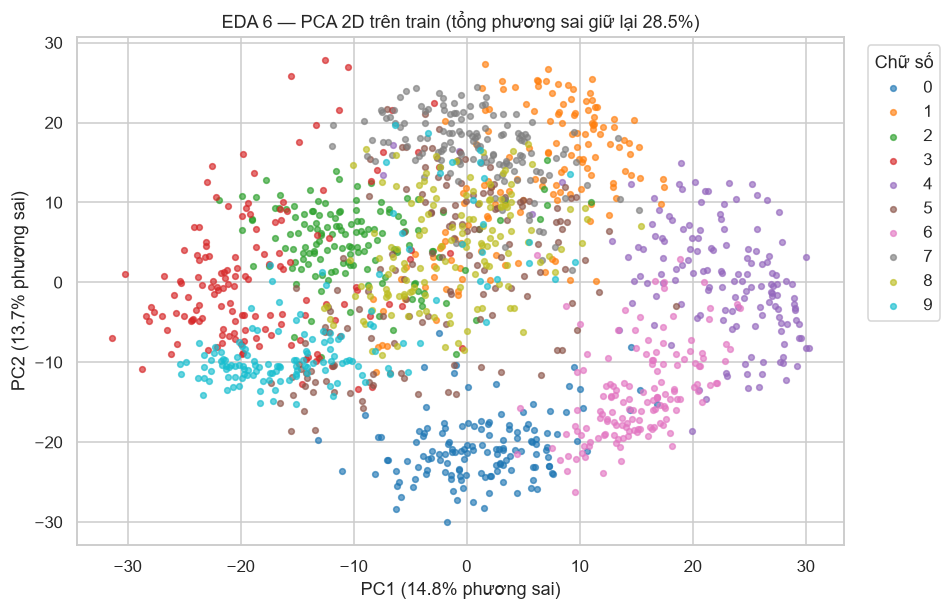

In [11]:
# PCA tự center; giữ pixel thô để quan sát phương sai trên cùng miền 0–16.
pca_eda = PCA(n_components=2, svd_solver="full", random_state=SEED)
train_2d = pca_eda.fit_transform(X_train)
fig, ax = plt.subplots(figsize=(9, 6))
palette = sns.color_palette("tab10", n_colors=10)
for label in LABELS:
    mask = y_train.to_numpy() == label
    ax.scatter(train_2d[mask, 0], train_2d[mask, 1], s=14, alpha=0.65, color=palette[label], label=str(label))
ratios = pca_eda.explained_variance_ratio_
ax.set(title=f"EDA 6 — PCA 2D trên train (tổng phương sai giữ lại {ratios.sum():.1%})",
       xlabel=f"PC1 ({ratios[0]:.1%} phương sai)", ylabel=f"PC2 ({ratios[1]:.1%} phương sai)")
ax.legend(title="Chữ số", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure(fig, "eda_06_pca_2d.png")
pd.DataFrame(train_2d, index=X_train.index, columns=["PC1", "PC2"]).assign(label=y_train).to_csv(OUT / "train_pca_2d.csv", index_label="sample_index")


**Nhận định EDA 6 (nhóm tự viết):** TODO — phương sai giữ lại và chồng lấn 2D; không dùng độ tách trên hình để kết luận accuracy.


## 6. Baseline chính: Logistic Regression trên pixel thô

Giữ pixel thô để trả lời trực tiếp câu hỏi baseline của đề tài và làm mốc cố định. Không khẳng định
Logistic Regression không cần scaling; scaling có thể thay đổi hội tụ và regularization. Lựa chọn
`passthrough` ở baseline là thiết kế đối chứng. Không biến baseline thành mô hình đã tuning.

**TODO nhóm:** tạo Pipeline có hai bước tên `scale`, `clf`; `scale='passthrough'`,
`clf` là LogisticRegression với `max_iter=3000`, `solver='lbfgs'`, seed 42 và C mặc định.
Nếu có ConvergenceWarning, ghi lại và điều tra trên train, không bỏ qua cảnh báo.
DummyClassifier(strategy='most_frequent') chỉ là mốc phụ tùy chọn, không thay baseline chính.

API: [Pipeline](https://scikit-learn.org/1.7/modules/generated/sklearn.pipeline.Pipeline.html),
[LogisticRegression](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html).


In [12]:
def make_baseline():
    # TODO SV-01: tự tạo và trả về Pipeline chưa fit theo hướng dẫn trên.
    raise NotImplementedError("SV-01: nhóm tự triển khai baseline pixel thô")


## 7. Hai mô hình so sánh: KNN và MLP bằng Pipeline

**TODO nhóm:** `make_comparison_models()` trả dict `{'knn': pipeline, 'mlp': pipeline}` chưa fit,
hai bước `scale`, `clf`. KNN dùng StandardScaler và KNeighborsClassifier; MLP dùng StandardScaler
và MLPClassifier(**MLP_INITIAL). Không đưa PCA EDA vào Pipeline phân loại.

StandardScaler học mean/std từ train trong từng fold; không fit_transform toàn bộ X_train rồi CV.
KNN nhạy với khoảng cách; MLP nhạy với thang đầu vào khi tối ưu. Kiểm chứng lợi ích bằng mục 8.
Thay scaler có thể đổi trọng số tương đối các vị trí pixel, không chỉ thay đơn vị.
KNN chuẩn hóa là cấu hình được đặt trước; không phát sinh thêm grid scaler cho KNN trong phase này.

API: [StandardScaler](https://scikit-learn.org/1.7/modules/generated/sklearn.preprocessing.StandardScaler.html),
[KNN](https://scikit-learn.org/1.7/modules/generated/sklearn.neighbors.KNeighborsClassifier.html).


In [13]:
def make_comparison_models():
    # TODO SV-02: tạo KNN và MLP đúng bước scale/clf; MLP_INITIAL ở mục 10.
    raise NotImplementedError("SV-02: nhóm tự triển khai hai Pipeline")


## 8. Thí nghiệm MLP có/không chuẩn hóa

**TODO nhóm:** dùng cấu hình MLP_INITIAL cố định, chỉ thay `scale` giữa `passthrough` và
StandardScaler. Dùng clone để không chia sẻ trạng thái fit; cùng `cv_splits`, seed, max_iter,
early stopping, solver và số luồng. Không dùng test. Với cross_validate, scoring gồm accuracy,
precision_macro, recall_macro, f1_macro. Trả DataFrame dài, mỗi hàng một fold/điều kiện:
`scaling, fold, accuracy, precision_macro, recall_macro, f1_macro, fit_time_s`.
Ghi mean/std (ddof=0) và chênh lệch F1 theo fold; chỉ mô tả, không suy diễn kiểm định thống kê.

Quy tắc đặt trước: chọn scaler MLP có mean CV macro F1 cao hơn; nếu hòa, chọn StandardScaler.
Sau đó chỉ tuning hidden_layer_sizes/alpha; không lẫn tác động scaling với thay kiến trúc.
Folds dùng lại khi tuning nên kết quả CV có thiên lệch lựa chọn, test cuối là kiểm tra độc lập.


In [14]:
def run_scaling_experiment(X_train, y_train, cv_splits):
    # TODO SV-03: chạy hai Pipeline đối chứng chỉ trên train/CV, trả bảng đủ 10 hàng.
    raise NotImplementedError("SV-03: nhóm tự triển khai đối chứng chuẩn hóa")


## 9. CV và GridSearchCV với grid nhỏ

**TODO nhóm:** `run_cv_searches` nhận models (baseline + knn + mlp), bảng đối chứng scaling,
train và cv_splits. Chọn scaler MLP theo quy tắc mục 8. Baseline dùng cross_validate;
KNN và MLP dùng GridSearchCV trên toàn Pipeline, `scoring='f1_macro'`, `cv=cv_splits`,
`n_jobs=1`, `error_score='raise'`, `refit=False`, `return_train_score=True`.
Ví dụ cú pháp API rời: `GridSearchCV(estimator=..., param_grid=..., cv=..., scoring=...)`;
nhóm tự viết lệnh hoàn chỉnh và `.fit(X_train, y_train)`.

Grid KNN 6 cấu hình ×5 =30 fits. Grid MLP 4×5 =20 fits. Đối chứng scaling 2×5=10 fits;
baseline CV 5 fits. Chưa tính learning curve và fit cuối. Không mở rộng grid chỉ để nâng điểm test.
Đo wall time quanh mỗi `.fit` tìm kiếm, không lấy `mean_fit_time` thay thời gian tuning tổng.
Với scoring đơn, refit=False vẫn dùng được best_params_/best_index_; không có best_estimator_.
Trả Pipeline **chưa fit** bằng clone + set_params, sau đó mục 12 mới đo fit cuối một lần.

Hợp đồng trả về `(templates, cv_summary, cv_details, tuning_times)`:

- templates: dict logreg_raw/knn/mlp → Pipeline chưa fit, tham số/scaler đã khóa bằng CV.
- cv_summary: DataFrame đúng 3 hàng, cột `model, cv_f1_macro_mean, cv_f1_macro_std` (ddof=0).
- cv_details: dict tên → DataFrame; baseline lưu điểm từng fold, grid lưu toàn bộ cv_results_.
- tuning_times: dict tên → số giây tuning; baseline không tuning ghi 0 (CV vẫn có chi phí, ghi ở cv_details).

API: [GridSearchCV](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.GridSearchCV.html),
[cross_validate](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.cross_validate.html).


In [15]:
KNN_GRID = {"clf__n_neighbors": [3, 5, 7], "clf__weights": ["uniform", "distance"]}
MLP_GRID = {"clf__hidden_layer_sizes": [(64,), (64, 32)], "clf__alpha": [0.0001, 0.001]}


def run_cv_searches(models, scaling_results, X_train, y_train, cv_splits):
    # TODO SV-04: CV baseline, chọn scaler bằng CV, GridSearchCV KNN/MLP và xuất đủ chi tiết.
    raise NotImplementedError("SV-04: nhóm tự triển khai CV và tuning")


## 10. Cấu hình MLP ban đầu và early stopping

Cấu hình bắt buộc `(64,32)`, relu, adam, early_stopping=True. `max_iter` là số epoch tối đa,
không phải bảo đảm chạy đủ. MLP giữ validation nội bộ từ phần train của mỗi fold; validation
score nội bộ là accuracy, không phải CV macro F1. Scaler trong Pipeline fit trên toàn phần train
của fold trước khi MLP tự chia validation nội bộ: cần nêu giới hạn này, không xem đó là test độc lập.
Outer validation của CV và test cuối vẫn không tham gia fit scaler.

API: [MLPClassifier](https://scikit-learn.org/1.7/modules/generated/sklearn.neural_network.MLPClassifier.html).
Nhóm giải thích số neuron/lớp, activation, alpha, early stopping và max_iter khi vấn đáp.


In [16]:
MLP_INITIAL = {"hidden_layer_sizes": (64, 32), "activation": "relu", "solver": "adam",
               "early_stopping": True, "validation_fraction": 0.1, "n_iter_no_change": 15,
               "max_iter": 300, "random_state": SEED}
print("Cấu hình khởi đầu, chưa fit:", MLP_INITIAL)


Cấu hình khởi đầu, chưa fit: {'hidden_layer_sizes': (64, 32), 'activation': 'relu', 'solver': 'adam', 'early_stopping': True, 'validation_fraction': 0.1, 'n_iter_no_change': 15, 'max_iter': 300, 'random_state': 42}


## 11. Độ đo đánh giá và classification report

Mục này **định nghĩa hàm**, chưa predict test. Chỉ gọi sau khi khóa mô hình tại mục 15.
**TODO nhóm:** tính accuracy; precision, recall, F1 với average='macro', labels=LABELS,
zero_division=0. classification_report với labels=LABELS, output_dict=True, zero_division=0.
Trả `(metrics, report)`, metrics có `accuracy, precision_macro, recall_macro, f1_macro`;
report là dict thật từ API. CV mean/std lấy từ train ở mục 9, không nhầm với điểm test.
Không diễn giải zero_division=0 như bằng chứng mô hình tốt; đó là quy ước khi mẫu số bằng 0.


In [17]:
def evaluate_predictions(y_true, y_pred):
    # TODO SV-05: tính đủ 4 độ đo và report; không dùng điểm test để chọn lại mô hình.
    raise NotImplementedError("SV-05: nhóm tự triển khai đánh giá")


## 12. Đo chi phí fit cuối, predict, tuning và dung lượng Pipeline

Hàm hỗ trợ dưới clone Pipeline đã chọn siêu tham số, fit trên cùng train, cùng test và máy.
Giới hạn thư viện BLAS/OpenMP ở 1 luồng; KNN/GridSearchCV cũng đặt n_jobs=1.
Fit cuối đo một lần (không bao gồm CV/tuning/serialize); predict có 1 warm-up và 5 lần đo,
báo median cùng từng lần. Đây là đo trên máy hiện tại, không khẳng định tổng quát.
Dung lượng là bytes joblib nén mức 3 của cả Pipeline, tính ngoài thời gian fit/predict.
Chưa gọi hàm với test cho tới mục 15. Tuning wall time ở mục 9 được báo riêng.


In [18]:
def measure_final_pipeline(template, X_train, y_train, X_test):
    fitted = clone(template)
    with threadpool_limits(limits=1):
        start = perf_counter()
        fitted.fit(X_train, y_train)
        fit_time = perf_counter() - start
        fitted.predict(X_test)  # warm-up, không tính vào median
        durations = []
        for _ in range(5):
            start = perf_counter()
            prediction = fitted.predict(X_test)
            durations.append(perf_counter() - start)
    buffer = BytesIO()
    joblib.dump(fitted, buffer, compress=3)
    blob = buffer.getvalue()
    costs = {"final_fit_time_s": fit_time, "predict_median_time_s": float(np.median(durations)),
             "predict_repeats_s": durations, "pipeline_bytes": len(blob)}
    return fitted, prediction, costs, blob


## 13. Ma trận nhầm lẫn, cặp nhầm và ảnh dự đoán sai

**TODO nhóm:** sau khóa mô hình, gọi confusion_matrix(..., labels=LABELS). Vẽ bằng
ConfusionMatrixDisplay; trục hàng nhãn thật, cột dự đoán; tiêu đề ghi tên mô hình và tập test.
Xuất ma trận số đếm. Tách các ô ngoài đường chéo có count>0, xếp giảm dần.
Quy ước cặp có hướng `true_label → predicted_label`; nếu gộp a↔b phải cộng hai ô và ghi rõ.
Không hard-code cặp dễ nhầm từ kiến thức bên ngoài.

Trả `(cm_frame, pairs, mistakes)`:
cm_frame 10×10 có index/columns 0–9; pairs có `true_label, predicted_label, count`;
mistakes có `sample_index, true_label, predicted_label`. Hiển thị tối đa 12 ảnh sai theo
thứ tự test, tiêu đề id/thật/dự đoán; thang pixel 0–16, nhãn hàng/cột, colorbar.
Lưu hình vào FIGURES bằng save_figure. Nếu không có lỗi, trả bảng rỗng có cột đúng và ghi
“không có mẫu sai trong test này”; không dựng lỗi giả. Không xóa ảnh sai hoặc quay lại tuning.


In [19]:
def analyze_errors(model_name, X_test, y_test, prediction):
    # TODO SV-06: tự tạo confusion matrix, bảng cặp nhầm, ảnh sai và các hình có chú thích.
    raise NotImplementedError("SV-06: nhóm tự triển khai phân tích lỗi")


**Nhận định nhóm cho từng mô hình:** TODO — cặp có hướng, số lần, ví dụ ảnh, giả thuyết có giới hạn.


## 14. Learning curve và lịch sử học MLP

**TODO nhóm:** draw_learning_curves(templates, X_train, y_train, cv_splits) dùng learning_curve
với Pipeline chưa fit, cv_splits, scoring='f1_macro', train_sizes=[0.2,0.4,0.6,0.8,1.0],
shuffle=True, random_state=42, n_jobs=1, error_score='raise'. Chỉ dùng train, tuyệt đối không test.
Trả DataFrame `model, train_size, train_mean, train_std, validation_mean, validation_std` (ddof=0);
vẽ đường train và validation cùng dải ±1 std cho cả 3 mô hình, đủ tiêu đề, trục và legend.
Kích thước là số mẫu train **trong fold**, không phải toàn dataset.

plot_mlp_history(fitted_mlp): lấy bước clf; vẽ loss_curve_ theo iteration và validation_scores_
nếu tồn tại. Dùng hai panel riêng: loss và accuracy validation nội bộ khác đơn vị. Nếu không có
lịch sử, ghi rõ nguyên nhân và không giả lập. Early stopping khôi phục trọng số tốt nhất;
iteration cuối trong lịch sử không nhất thiết là mô hình cuối được giữ.

Không kết luận có overfitting nếu chưa thấy bằng chứng. Khoảng cách train/validation và diễn biến
theo số mẫu chỉ là gợi ý; đường loss train giảm không tự chứng minh overfitting. Các curve dùng
cùng CV đã chọn hyperparameter nên cũng có thiên lệch lựa chọn. Chưa fit curve trong khung hỗ trợ.


In [20]:
def draw_learning_curves(templates, X_train, y_train, cv_splits):
    # TODO SV-07: tự chạy learning_curve, vẽ và trả bảng các điểm thật.
    raise NotImplementedError("SV-07: nhóm tự triển khai learning curve")


def plot_mlp_history(fitted_mlp):
    # TODO SV-08: tự vẽ loss / validation accuracy từ estimator đã fit.
    raise NotImplementedError("SV-08: nhóm tự triển khai lịch sử học MLP")


**Nhận định learning curve và lịch sử MLP (nhóm tự viết):** TODO — dẫn số mẫu/iteration, nêu bằng chứng hoặc nói chưa đủ bằng chứng quá khớp.


## 15. Khóa lựa chọn bằng CV rồi mới đánh giá cuối trên test

**TODO nhóm:** choose_model_by_cv chỉ được nhận cv_summary; xếp mean macro F1 giảm,
model tăng khi hòa tuyệt đối; trả tên mô hình. Không nhận X_test/y_test. Viết nhận định về
độ ổn định (std), chi phí và giới hạn dù quy tắc chọn vẫn giữ nguyên. Không thay metric sau khi xem điểm.

Ô điều phối hỗ trợ chỉ chạy khi cờ True và các TODO đã được nhóm hoàn thành. Ghi file
selection_lock.json trước mọi predict test; lưu đúng tham số đã khóa. Learning curve vẫn chỉ train.
Đánh giá cả 3 mô hình trên test để so sánh sau khóa; tên mô hình thắng không được đổi theo điểm test.
Phân tích nhầm lẫn test chỉ dùng cho báo cáo, không mở vòng tuning mới.


In [21]:
def choose_model_by_cv(cv_summary):
    # TODO SV-09: tự chọn theo quy tắc đã đặt trước; không được đọc test.
    raise NotImplementedError("SV-09: nhóm tự triển khai lựa chọn bằng CV")


In [22]:
experiment_complete = False
if RUN_STUDENT_EXPERIMENTS:
    assert CLEANING_DECISION.strip(), "Nhóm phải ghi quyết định xử lý dữ liệu tại mục 3."
    assert STUDENT_PROTOCOL_NOTE.strip(), "Nhóm phải ghi xác nhận tiêu chí/thí nghiệm trước khi chạy."
    models = {"logreg_raw": make_baseline(), **make_comparison_models()}
    assert set(models) == {"logreg_raw", "knn", "mlp"}
    assert all(isinstance(model, Pipeline) for model in models.values())
    with threadpool_limits(limits=1):
        scaling_results = run_scaling_experiment(X_train, y_train, cv_splits)
        templates, cv_summary, cv_details, tuning_times = run_cv_searches(
            models, scaling_results, X_train, y_train, cv_splits)
    assert set(templates) == {"logreg_raw", "knn", "mlp"}
    assert set(cv_summary["model"]) == set(templates) and len(cv_summary) == 3
    assert np.isfinite(cv_summary[["cv_f1_macro_mean", "cv_f1_macro_std"]].to_numpy()).all()
    selected_name = choose_model_by_cv(cv_summary)
    expected_name = cv_summary.sort_values(["cv_f1_macro_mean", "model"], ascending=[False, True]).iloc[0]["model"]
    assert selected_name == expected_name, "Lựa chọn không đúng quy tắc CV đã đặt trước."
    selection_lock = {"selected_model": selected_name, "rule": SELECTION_RULE,
                      "cv_summary": cv_summary.to_dict(orient="records"),
                      "parameters": {name: repr(p.get_params(deep=True)) for name, p in templates.items()},
                      "cleaning_decision": CLEANING_DECISION, "student_protocol_note": STUDENT_PROTOCOL_NOTE,
                      "test_used_at_lock": False, "data_sha256": DATA_SHA256,
                      "locked_at_utc": datetime.now(timezone.utc).isoformat()}
    (OUT / "selection_lock.json").write_text(json.dumps(selection_lock, indent=2, ensure_ascii=False), encoding="utf-8")
    with threadpool_limits(limits=1):
        curve_results = draw_learning_curves(templates, X_train, y_train, cv_splits)
    final_pipelines, pipeline_blobs, reports, error_tables, timing_details = {}, {}, {}, {}, {}
    result_rows, prediction_frames = [], []
    for name, template in templates.items():
        fitted, prediction, costs, blob = measure_final_pipeline(template, X_train, y_train, X_test)
        metrics, report = evaluate_predictions(y_test, prediction)
        cm_frame, pairs, mistakes = analyze_errors(name, X_test, y_test, prediction)
        final_pipelines[name], pipeline_blobs[name], reports[name] = fitted, blob, report
        error_tables[name] = (cm_frame, pairs, mistakes)
        timing_details[name] = costs
        result_rows.append({"model": name, **metrics,
                            "final_fit_time_s": costs["final_fit_time_s"],
                            "predict_median_time_s": costs["predict_median_time_s"],
                            "tuning_time_s": tuning_times[name], "pipeline_bytes": costs["pipeline_bytes"]})
        prediction_frames.append(pd.DataFrame({"model": name, "sample_index": X_test.index,
                                                "true_label": y_test.to_numpy(), "predicted_label": prediction}))
    plot_mlp_history(final_pipelines["mlp"])
    final_results = pd.DataFrame(result_rows).merge(cv_summary, on="model", validate="one_to_one")
    display(final_results)
    print("Mô hình đã chọn bằng CV, giữ nguyên sau test:", selected_name)
    experiment_complete = True
else:
    print("CHƯA CHẠY mô hình/CV/tuning/test/learning curve: các TODO SV-01…SV-09 thuộc nhóm.")


CHƯA CHẠY mô hình/CV/tuning/test/learning curve: các TODO SV-01…SV-09 thuộc nhóm.


**Nhận định cuối do nhóm tự viết:** TODO — baseline đạt bao nhiêu; MLP cải thiện, ngang hay kém;
độ ổn định CV; chi phí thực tế; giới hạn Digits nhỏ, ảnh 8×8, chia ngẫu nhiên không bảo đảm
độc lập người viết. Không cam kết áp dụng trực tiếp cho ảnh chụp/chữ viết ngoài bộ dữ liệu.


## 16. Lưu Pipeline và xuất kết quả thực tế

Chỉ xuất mô hình và điểm số khi thực nghiệm thực sự hoàn tất; không tạo file mô hình giả.
Mỗi run có thư mục riêng để bảo toàn các kết quả trước. Toàn bộ Pipeline (gồm scaler nếu có)
được joblib serialize; chạy thử tải lại và đối chiếu predict trước khi dùng demo sau này.
Chỉ load file joblib do nhóm tin cậy. Không triển khai Streamlit trong notebook này.


In [23]:
if experiment_complete:
    MODEL_OUT.mkdir(parents=True, exist_ok=False)
    final_results.to_csv(OUT / "model_comparison.csv", index=False)
    scaling_results.to_csv(OUT / "mlp_scaling_cv.csv", index=False)
    cv_summary.to_csv(OUT / "cv_summary.csv", index=False)
    curve_results.to_csv(OUT / "learning_curve.csv", index=False)
    pd.concat(prediction_frames, ignore_index=True).to_csv(OUT / "test_predictions.csv", index=False)
    for name in final_pipelines:
        cv_details[name].to_csv(OUT / f"cv_details_{name}.csv", index=False)
        pd.DataFrame(reports[name]).T.to_csv(OUT / f"classification_report_{name}.csv")
        cm_frame, pairs, mistakes = error_tables[name]
        cm_frame.to_csv(OUT / f"confusion_matrix_{name}.csv", index_label="true_label")
        pairs.to_csv(OUT / f"confusion_pairs_{name}.csv", index=False)
        mistakes.to_csv(OUT / f"misclassified_{name}.csv", index=False)
        model_path = MODEL_OUT / f"{name}.joblib"
        # Blob này chính là kết quả joblib.dump(Pipeline, compress=3) ở mục 12.
        model_path.write_bytes(pipeline_blobs[name])
        restored = joblib.load(model_path)
        assert np.array_equal(restored.predict(X_test), final_pipelines[name].predict(X_test))
        assert model_path.stat().st_size == timing_details[name]["pipeline_bytes"]
    (OUT / "timing_details.json").write_text(json.dumps(timing_details, indent=2), encoding="utf-8")
    mlp_clf = final_pipelines["mlp"].named_steps["clf"]
    history = {"loss_curve": getattr(mlp_clf, "loss_curve_", None),
               "validation_scores": getattr(mlp_clf, "validation_scores_", None),
               "n_iter": int(mlp_clf.n_iter_), "best_validation_score": getattr(mlp_clf, "best_validation_score_", None)}
    (OUT / "mlp_history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
    (MODEL_OUT / "metadata.json").write_text(json.dumps({"selected_model": selected_name,
        "run_id": RUN_ID, "environment": environment, "data_sha256": DATA_SHA256,
        "input_shape": [None, 64], "pixel_range": [0, 16], "labels": LABELS.tolist(),
        "selection_lock": str(OUT / "selection_lock.json")}, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Đã xuất kết quả thật:", OUT, "và", MODEL_OUT)
status = {"support_run_completed": True, "student_experiments_completed": experiment_complete,
          "selected_model": selected_name if experiment_complete else None,
          "pending_student_tasks": [] if experiment_complete else [f"SV-{i:02d}" for i in range(1, 10)],
          "student_interpretations_reviewed": False, "ready_to_submit": False,
          "note": "Chạy hết khung không đồng nghĩa hoàn thành đồ án; nhóm cần nhận định và rà soát trước nộp."}
(OUT / "run_status.json").write_text(json.dumps(status, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.Series(status))


support_run_completed                                                            True
student_experiments_completed                                                   False
selected_model                                                                   None
pending_student_tasks               [SV-01, SV-02, SV-03, SV-04, SV-05, SV-06, SV-...
student_interpretations_reviewed                                                False
ready_to_submit                                                                 False
note                                Chạy hết khung không đồng nghĩa hoàn thành đồ ...
dtype: object

### Nhóm tự hoàn thành trước bàn giao/bảo vệ

- TODO SV-01…SV-09 và nhật ký làm sạch; chạy lại từ kernel sạch, kiểm tra mọi warning.
- 6 nhận định EDA; giải thích kết quả CV/test, lỗi và giới hạn; không nhờ AI viết kết luận thay nhóm.
- Trả lời 5 câu hỏi: biểu diễn/chuẩn hóa (2,5,8); baseline và MLP (6–11,15); nhầm lẫn (13);
  learning curve (14); chi phí/độ chính xác (12,15–16).
- Đối chiếu `docs/REQUIREMENTS_MAP.md`; tự viết báo cáo/slide, bổ sung phân công thật.
- Ghi lệnh, kết quả, lỗi, Git trong HANDOFF.md; ghi đúng đóng góp người/AI trong AI_USAGE.md.

**Hiện trạng:** khung hỗ trợ được phép chạy liên tục; thực nghiệm cốt lõi chưa triển khai
không được xem là bài hoàn chỉnh. Giữ bằng chứng chạy và không thay số liệu thủ công.
